# Home Credit Default Risk — Final Model Evaluation

## 1. Introduction

This notebook evaluates the final XGBoost probability-of-default
model on the previously untouched test dataset.

The model and decision threshold were selected using training
and validation data.

The final selected model is XGBoost with shallow decision trees,
and the decision threshold is 0.086, chosen to minimize
hypothetical classification costs on the validation dataset.

The objective is to evaluate how well the model generalizes
to unseen borrowers using:

- ROC-AUC and PR-AUC
- Brier score and probability calibration
- Precision, recall, and F1-score
- Confusion matrix
- Hypothetical classification costs
- Risk-ranking performance

No additional model tuning or threshold optimization will be
performed using the test dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

from pathlib import Path
from scipy import sparse

from google.colab import drive
drive.mount("/content/drive")

PROJECT_PATH = Path("/content/drive/MyDrive/Home Credit Default Risk")
PROCESSED_PATH = PROJECT_PATH / "data" / "processed"
MODEL_PATH = PROJECT_PATH / "models"

# Load untouched test dataset
X_test = sparse.load_npz(
    PROCESSED_PATH / "X_test.npz"
)

y_test = pd.read_csv(
    PROCESSED_PATH / "y_test.csv"
).squeeze("columns")

print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)
print("Test default rate:", round(y_test.mean(), 4))

Mounted at /content/drive
Test features: (46127, 318)
Test labels: (46127,)
Test default rate: 0.0807


In [2]:
# Load trained XGBoost model
final_model = joblib.load(
    MODEL_PATH / "xgboost_tuned.joblib"
)

# Load frozen configuration
with open(MODEL_PATH / "final_model_config.json", "r") as f:
    final_config = json.load(f)

final_threshold = final_config["decision_threshold"]

print("Model:", final_config["model"])
print("Configuration:", final_config["configuration"])
print("Decision threshold:", final_threshold)
print("Model features:", final_model.n_features_in_)

Model: XGBoost
Configuration: Shallow Trees
Decision threshold: 0.086
Model features: 318


## 2. Final Test Set Evaluation

The selected XGBoost model is evaluated on the previously untouched
test dataset.

Predicted probabilities are used to calculate ROC-AUC, PR-AUC,
and Brier score. Binary classifications are generated using the
previously selected decision threshold of 0.086.

These results provide an independent estimate of the model's
predictive performance and decision-making effectiveness. But time and time again it o

In [3]:
# Predict default probabilities
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the frozen decision threshold
y_test_pred = (y_test_prob >= final_threshold).astype(int)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_test_prob))
print("Borrowers flagged:", y_test_pred.sum())

Predictions generated successfully!
Number of predictions: 46127
Borrowers flagged: 14022


In [4]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

test_roc_auc = roc_auc_score(y_test, y_test_prob)
test_pr_auc = average_precision_score(y_test, y_test_prob)
test_brier = brier_score_loss(y_test, y_test_prob)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
).ravel()

test_results = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Brier Score",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Test Result": [
        test_roc_auc,
        test_pr_auc,
        test_brier,
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

display(test_results.round(4))

print("\nConfusion Matrix")
print(f"True Negatives:  {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives:  {tp:,}")

,Metric,Test Result
0,ROC-AUC,0.7691
1,PR-AUC,0.2546
2,Brier Score,0.0672
3,Accuracy,0.7236
4,Precision,0.1782
5,Recall,0.6711
6,F1-Score,0.2816



Confusion Matrix
True Negatives:  30,880
False Positives: 11,523
False Negatives: 1,225
True Positives:  2,499


### Final Test Evaluation Results

The final XGBoost model was evaluated on the previously untouched
test dataset containing 46,127 observations.

The model achieved a ROC-AUC of 0.7691, PR-AUC of 0.2546, and
Brier score of 0.0672.

These results were closely aligned with validation performance,
suggesting that the model generalizes reasonably well to unseen
observations from the same dataset.

Using the frozen decision threshold of 0.086, the model achieved
67.11% recall and 17.82% precision.

The confusion matrix contained 2,499 true positives, 30,880 true
negatives, 11,523 false positives, and 1,225 false negatives.

Under the hypothetical classification costs of $500 per false
positive and $5,000 per false negative, the total test-set cost
was $11,886,500.

These results demonstrate the importance of selecting decision
thresholds based on business objectives rather than relying on
the default 0.50 cutoff.

The test set was used exclusively for final evaluation, with
no additional model tuning or threshold optimization.

## 3. Business Baseline Comparison

To assess the practical value of the selected XGBoost decision
rule, its hypothetical classification cost is compared against
two simple baseline strategies:

1. Flag Nobody: Classify all borrowers as low risk.
2. Flag Everybody: Classify all borrowers as high risk.
3. XGBoost: Apply the frozen 0.086 decision threshold.

All strategies are evaluated on the same test dataset using
the previously specified hypothetical costs of $500 per false
positive and $5,000 per false negative.

This comparison evaluates the economic usefulness of the
classification decisions under a simplified cost framework.

In [5]:
# Previously defined hypothetical costs
COST_FP = final_config["false_positive_cost"]
COST_FN = final_config["false_negative_cost"]

# Actual number of positive and negative cases
total_defaults = int(y_test.sum())
total_non_defaults = int((y_test == 0).sum())

# Strategy 1: Flag nobody
cost_flag_nobody = total_defaults * COST_FN

# Strategy 2: Flag everybody
cost_flag_everybody = total_non_defaults * COST_FP

# Strategy 3: XGBoost with frozen threshold
cost_xgboost = fp * COST_FP + fn * COST_FN

baseline_comparison = pd.DataFrame({
    "Strategy": [
        "Flag Nobody",
        "Flag Everybody",
        "XGBoost (8.6%)"
    ],
    "Total Cost": [
        cost_flag_nobody,
        cost_flag_everybody,
        cost_xgboost
    ]
})

baseline_comparison["Cost Reduction vs Flag Nobody (%)"] = (
    (cost_flag_nobody - baseline_comparison["Total Cost"])
    / cost_flag_nobody * 100
)

display(baseline_comparison.round(2))

,Strategy,Total Cost,Cost Reduction vs Flag Nobody (%)
0,Flag Nobody,18620000,0.00
1,Flag Everybody,21201500,-13.86
2,XGBoost (8.6%),11886500,36.16


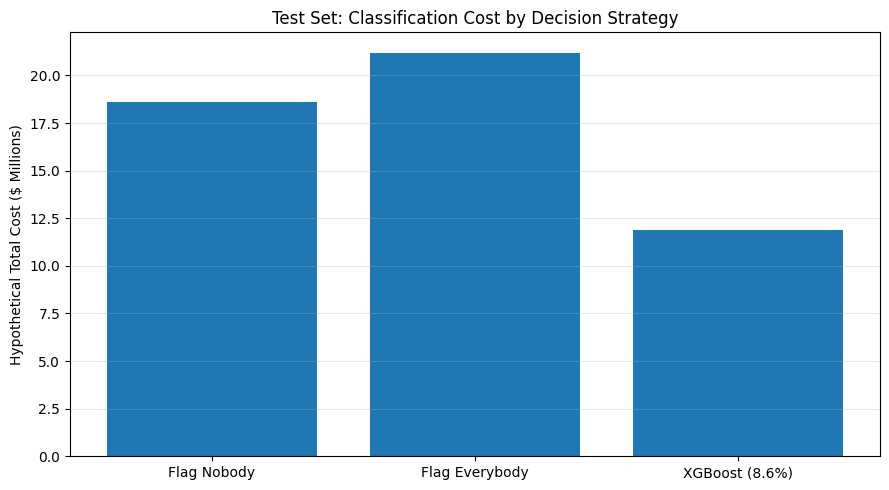

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(
    baseline_comparison["Strategy"],
    baseline_comparison["Total Cost"] / 1_000_000
)

plt.ylabel("Hypothetical Total Cost ($ Millions)")
plt.title("Test Set: Classification Cost by Decision Strategy")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Business Impact Analysis

The final XGBoost decision strategy achieved a hypothetical
classification cost of $11,886,500 on the test dataset.

This represents a 36.16% reduction compared with flagging
no borrowers and a 43.94% reduction compared with flagging
all borrowers.

The results demonstrate how probability predictions can be
translated into actionable decisions using cost-sensitive
classification.

Rather than optimizing accuracy alone, the selected decision
threshold prioritizes identifying borrowers at risk of
repayment difficulties while accounting for the assumed
financial consequences of classification errors.

These results are based on hypothetical fixed costs and
simplified decision strategies. They do not represent
realized financial savings or actual lending profitability.

## 4. Final Conclusion

This project developed and evaluated a machine learning
pipeline for predicting repayment difficulties using the
Home Credit Default Risk dataset.

The project included exploratory data analysis, feature
engineering, preprocessing, model comparison, hyperparameter
tuning, probability calibration assessment, model
interpretability, and cost-sensitive decision optimization.

Four modeling approaches were evaluated: Logistic Regression,
Random Forest, LightGBM, and XGBoost.

XGBoost was selected as the final model based on validation
performance, with a ROC-AUC of 0.7661 and PR-AUC of 0.2566.

On the previously untouched test dataset, XGBoost achieved:

- ROC-AUC: 0.7691
- PR-AUC: 0.2546
- Brier Score: 0.0672
- Precision: 17.82%
- Recall: 67.11%
- F1-Score: 0.2816

The similarity between validation and test performance
suggests reasonable generalization to unseen observations
from the same data distribution.

Using a validation-selected decision threshold of 0.086,
the model identified approximately 67% of borrowers who
experienced repayment difficulties.

Under hypothetical false-positive and false-negative costs
of $500 and $5,000, respectively, the model reduced
classification costs by 36.16% compared with flagging
no borrowers.

SHAP analysis provided insight into the model's predictions,
with external credit-related scores emerging as important
predictive features.

### Limitations

Several limitations should be considered:

1. The cost assumptions are hypothetical and do not reflect
   actual lending losses, recovery rates, or profitability.

2. The dataset uses a historical snapshot, so the model has
   not been evaluated under temporal distribution shifts.

3. Model performance was evaluated using a random holdout
   split rather than a prospective deployment setting.

4. Fairness, regulatory compliance, and potential
   discrimination would require additional investigation
   before any real-world credit decision application.

5. The target represents the dataset's repayment-difficulty
   outcome and should not automatically be interpreted as
   a regulatory definition of default.

### Future Improvements

Future work could include temporal validation, fairness
auditing, model monitoring, more realistic loss modeling,
and additional feature engineering using supplementary
Home Credit datasets.

Overall, the project demonstrates how machine learning,
statistical evaluation, model explainability, and
cost-sensitive optimization can be combined to support
financial risk decision-making.